Exploratory Data Analysis

Calculate the main bussiness KPIs

In [3]:
import pandas as pd

sales = pd.read_csv(
    r"C:\Users\Admin\Desktop\FreshChoice_Analytics\Data\processed\Sales_Clean.csv",
    parse_dates=["Invoice_Date"]
)

net_sales = sales["Total_Sales"].sum()

gross_sales = sales["Gross_Sales"].sum()

profit = sales["Profit"].sum()

cost = sales["Line_Cost"].sum()

orders = sales["Invoice_No"].nunique()

units_sold = sales["Quantity"].sum()

profit_margin = profit / net_sales * 100

average_order_value = net_sales / orders

print("Net Sales:", round(net_sales, 2))

print("Gross Sales:", round(gross_sales, 2))

print("Total Profit:", round(profit, 2))

print("Total Cost:", round(cost, 2))

print("Total Orders:", orders)

print("Units Sold:", units_sold)

print("Profit Margin (%):", round(profit_margin, 2))

print("Average Order Value:", round(average_order_value, 2))

Net Sales: 62576507.59
Gross Sales: 64467897.55
Total Profit: 18386080.35
Total Cost: 44190427.24
Total Orders: 26000
Units Sold: 89675
Profit Margin (%): 29.38
Average Order Value: 2406.79


Analyze monthly sales

In [4]:
#first aggregate sales by month
monthly_sales = (
    sales.groupby(
        sales["Invoice_Date"].dt.to_period("M")
    )["Total_Sales"]
    .sum()
)

print(monthly_sales)

Invoice_Date
2025-01    4970883.66
2025-02    4648934.74
2025-03    5416924.40
2025-04    5466783.64
2025-05    5088440.38
2025-06    4707871.15
2025-07    4766811.90
2025-08    5415395.73
2025-09    4892440.51
2025-10    4872672.08
2025-11    5908299.30
2025-12    6421050.10
Freq: M, Name: Total_Sales, dtype: float64


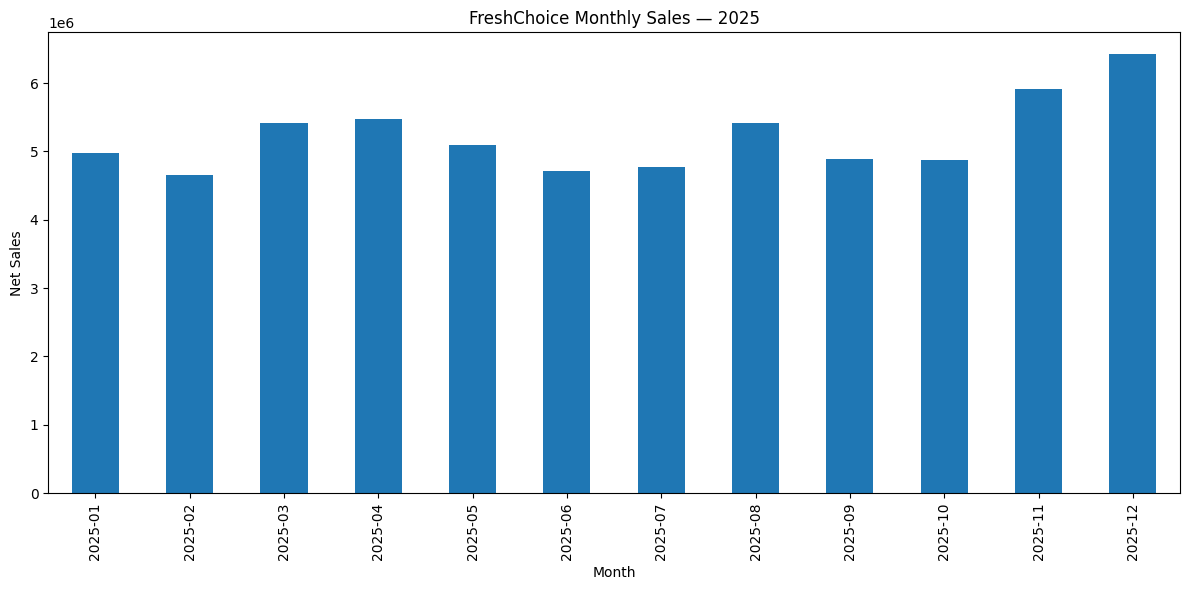

In [5]:
#visualize the results
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

monthly_sales.plot(kind="bar")

plt.title("FreshChoice Monthly Sales — 2025")

plt.xlabel("Month")

plt.ylabel("Net Sales")

plt.tight_layout()

plt.savefig(
    "outputs_monthly_sales.png",
    dpi=150
)

plt.show()

Observations

1.December is the month with the highest monthly sales.
2.February is the month with the lowest monthly sales.
3.the mothly sales seems to fluctuate mothly with a noticeble significant increase in the last few months.

Analyze daily sales trend

In [6]:
#aggregate the sales records into daily totals
daily_sales = (
    sales.groupby("Invoice_Date")
    .agg(
        Net_Sales=("Total_Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Invoice_No", "nunique")
    )
    .reset_index()
)

print(daily_sales.head())

  Invoice_Date  Net_Sales    Profit  Orders
0   2025-01-01  163960.25  51481.10      64
1   2025-01-02  154639.28  44140.44      62
2   2025-01-03  178047.23  51218.36      68
3   2025-01-04  179599.29  54542.05      67
4   2025-01-05  188281.56  51975.07      89


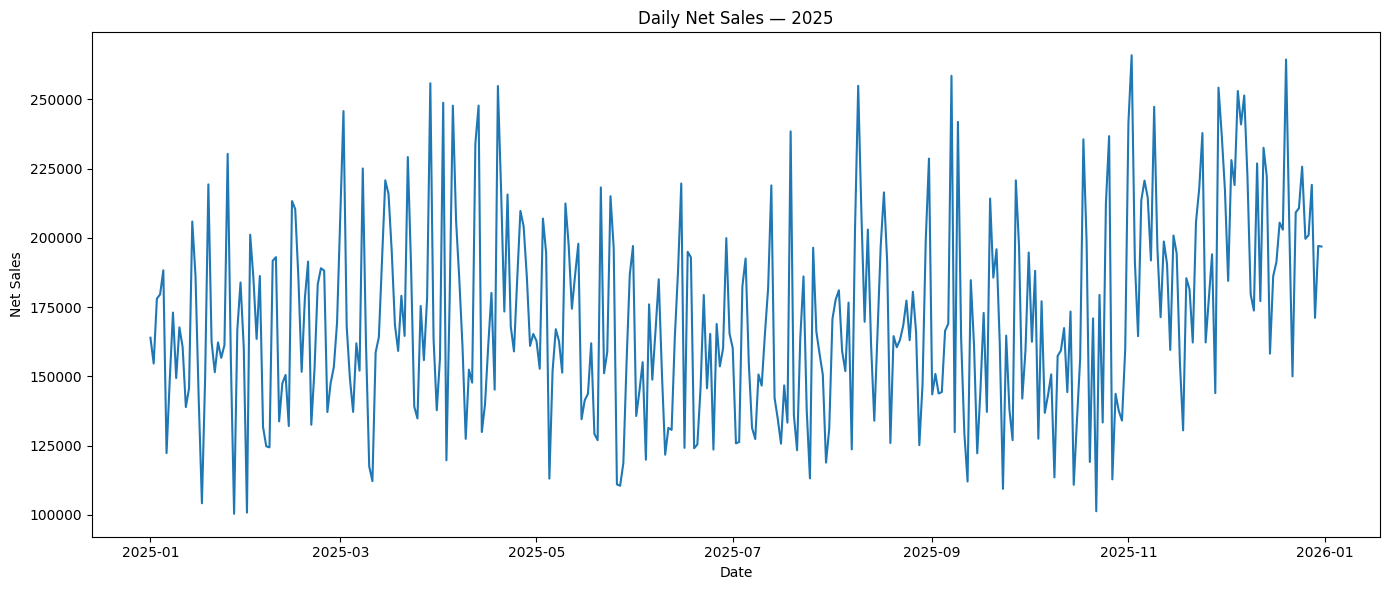

In [7]:
#plot the trend
plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales["Invoice_Date"],
    daily_sales["Net_Sales"]
)

plt.title("Daily Net Sales — 2025")

plt.xlabel("Date")

plt.ylabel("Net Sales")

plt.tight_layout()

plt.show()

Observations 
1,The amount of sales tend to fluctuate daily.

Analyze product categories

In [ ]:
#load the products table and join it to sales
products = pd.read_excel(
    r"C:\Users\Admin\Desktop\FreshChoice_Analytics\Data\FreshChoice_Analytics_Project_Dataset.xlsx",
    sheet_name="Products"
)

sales_products = sales.merge(
    products[["Product_ID", "Category"]],
    on="Product_ID",
    how="left",
    validate="many_to_one"
)

category_sales = (
    sales_products.groupby("Category")
    .agg(
        Net_Sales=("Total_Sales", "sum"),
        Profit=("Profit", "sum"),
        Units=("Quantity", "sum")
    )
    .sort_values("Net_Sales", ascending=False)
)

print(category_sales)
#The validate="many_to_one" argument checks that each product ID maps to one product record.

                 Net_Sales      Profit  Units
Category                                     
Snacks          9935953.11  2919938.35  13777
Bakery          7790517.19  2315134.26  10778
Produce         7307458.57  2139748.79  10646
Dairy           6986334.10  1817974.35   9216
Frozen          6839775.86  2089498.39   9477
Personal Care   6581212.84  1971522.43   9483
Beverages       6145637.38  1818415.28   9309
Household       6023698.38  1798983.93   9036
Meat & Seafood  4965920.16  1514864.57   7953


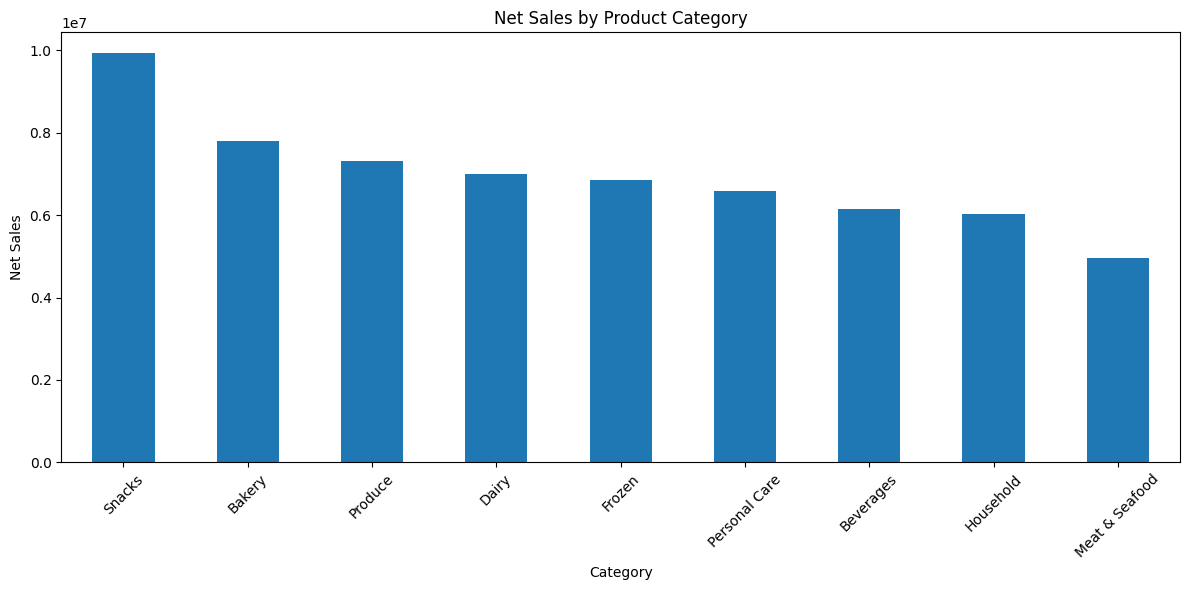

In [11]:
#visualize the results
category_sales["Net_Sales"].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Net Sales by Product Category")

plt.xlabel("Category")

plt.ylabel("Net Sales")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

Observations

1.Snacks has the highest net sales and also the highest profitability.
2.Meat has the lowest net sales and suubsequentl the lowest profitability.

Analyze store perfomance

In [13]:
stores = pd.read_excel(
    r"C:\Users\Admin\Desktop\FreshChoice_Analytics\Data\FreshChoice_Analytics_Project_Dataset.xlsx",
    sheet_name="Stores"
)

sales_stores = sales.merge(
    stores[["Store_ID", "Store_Name", "City", "Region"]],
    on="Store_ID",
    how="left",
    validate="many_to_one"
)

store_performance = (
    sales_stores.groupby(
        ["Store_ID", "Store_Name", "City", "Region"]
    )
    .agg(
        Net_Sales=("Total_Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .sort_values("Net_Sales", ascending=False)
)

print(store_performance)

                                                          Net_Sales  \
Store_ID Store_Name                City     Region                    
S001     FreshChoice Nairobi CBD   Nairobi  Nairobi      6550527.30   
S006     FreshChoice Thika Mall    Thika    Central      6385020.82   
S009     FreshChoice Machakos Town Machakos Eastern      6367555.57   
S007     FreshChoice Nyeri Town    Nyeri    Central      6309105.56   
S005     FreshChoice Eldoret CBD   Eldoret  Rift Valley  6253640.17   
S004     FreshChoice Kisumu Town   Kisumu   Nyanza       6205024.27   
S010     FreshChoice Meru Town     Meru     Eastern      6203738.91   
S002     FreshChoice Mombasa Town  Mombasa  Coast        6176099.41   
S008     FreshChoice Kakamega Town Kakamega Western      6098716.67   
S003     FreshChoice Nakuru Nyali  Nakuru   Rift Valley  6027078.91   

                                                             Profit  
Store_ID Store_Name                City     Region                   
S001   

Observations
1.The leading store in terms of net sales is FreshChoice Nairobi CBD.
2.The last store in terms of net sales is   FreshChoice Nakuru Nyali.

Analyze weekday versus weekend sales

In [14]:
daily_sales["Is_Weekend"] = (
    daily_sales["Invoice_Date"].dt.dayofweek >= 5
)

weekday_summary = (
    daily_sales.groupby("Is_Weekend")["Net_Sales"]
    .agg(["count", "mean", "median", "std"])
)

print(weekday_summary)

            count           mean     median           std
Is_Weekend                                               
False         261  159768.621916  159142.93  29604.248786
True          104  200739.396827  198845.41  32027.277388


Analyze customer segments

In [ ]:
customers = pd.read_excel(
    r"C:\Users\Admin\Desktop\FreshChoice_Analytics\Data\FreshChoice_Analytics_Project_Dataset.xlsx",
    sheet_name="Customers"
)

customer_sales = (
    sales.groupby("Customer_ID")
    .agg(
        Net_Sales=("Total_Sales", "sum"),
        Orders=("Invoice_No", "unique"),
        Profit=("Profit", "sum")
    )
    .reset_index()
)

customer_sales = customer_sales.merge(
    customers[["Customer_ID", "Customer_Segment"]],
    on="Customer_ID",
    how="left",
    validate="one_to_one"
)

segment_analysis = (
    customer_sales.groupby("Customer_Segment")
    .agg(
        Customers=("Customer_ID", "unique"),
        Total_Sales=("Net_Sales", "sum"),
        Average_Customer_Spend=("Net_Sales", "mean"),
        Orders=("Orders", "sum")
    )
)

print(segment_analysis)

                                                          Customers  \
Customer_Segment                                                      
Budget            [C00005, C00008, C00011, C00012, C00013, C0001...   
Family            [C00001, C00021, C00024, C00029, C00032, C0003...   
Premium           [C00002, C00003, C00014, C00022, C00023, C0002...   
Regular           [C00004, C00006, C00007, C00009, C00010, C0001...   

                  Total_Sales  Average_Customer_Spend  Orders  
Customer_Segment                                               
Budget            17741213.88            35200.821190    7300  
Family            12077376.98            35108.654012    5036  
Premium            8316556.99            35389.604213    3441  
Regular           24441359.74            34088.367838   10223  


Observations
1.The leading sales in terms of cuustomer segments is Budget.
2.The lowest sales in terms of customer segments is Regular.

My EDA delivarables
1.Monthly sales.
2.Daily sales trend.
3.Sales by category.
4.Sales or profit by store.
5.Sales by customer segment.